# Anguish – Lava (Harakim)

Anguish (Lava) puts a 30 s marker on the target. The caster's next **Blast** against that target
consumes the marker and is multiplied by 150–200%. The marker does nothing else: it deals no damage
and only Blast reads it.

| | |
|---|---|
| Class | Harakim |
| Target | Single hostile |
| Cost | 30 mana (not divided by 3 for Harakim), spent before the roll |
| Cooldown | none: Anguish adds no exhaust (it is refused while exhausted) |
| Landing roll | `chance_base(skill, 10, effective_resist(Resist))` |
| Duration | 30 s, or until the next Blast on the target |
| Effect | `compute_blast_damage`: `dam = 2p' · clamp(150 + ⌊m/2⌋, 150, 200) / 100`, with $m$ the caster's **raw** skill when the marker was placed |
| Source | `server/src/driver/skill/harakim.rs::skill_anguish_lava`, `anguish_preflight`; `driver/skill/blast.rs::compute_blast_damage` |

---

# Formula

With $m$ the raw Anguish (Lava) skill and $p'$ the Blast power after Immunity and race:

$$
k = \operatorname{clamp}\!\left(150 + \lfloor m/2 \rfloor,\ 150,\ 200\right)
\qquad
\text{dam} = \left\lfloor \frac{2p' \cdot k}{100} \right\rfloor
\qquad
\text{Blast cost} = \left\lfloor \frac{\lfloor \text{dam}/8 \rfloor + 5}{3} \right\rfloor
$$

The multiplier is applied before armor and before the splash, so the 75% splash doubles too.
Blast's mana cost is computed from the multiplied damage, so a consuming Blast costs about twice
as much.

$$
P(\text{marker lands}) = \frac{\operatorname{clamp}\!\left(\lfloor 10m/R_\text{eff}\rfloor,\ 0,\ 18\right) + 1}{20}
\quad (0 \text{ if } R_\text{eff} > \lfloor 3m/2 \rfloor)
$$

| Quantity | Breakpoint |
|---|---|
| Multiplier ceiling | ×2.00 from $m \ge 100$ (below the raise cap) |
| Floor | ×1.50 at $m \le 1$ |
| Combo cost at 105 | 30 (Anguish) + 19 (boosted Blast) = 49 mana, against 10 for a plain Blast |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
ANGUISH_COST = 30
MARKER_S = 30
EXHAUST_S = 6

# Model

In [2]:
def multiplier_pct(m):
    return mm.clamp(150 + mm.idiv(m, 2), 150, 200)


def blast_dam(pp, m=None):
    dam = np.asarray(pp) * 2
    if m is None:
        return dam
    return dam * multiplier_pct(m) // 100


def blast_cost(dam):
    return mm.idiv(np.asarray(dam) // 8 + 5, 3)


def p_marker(m, resist):
    return mm.p_chance_base(m, 10, resist)


def cycle(p, resist, armor=0, immun=0, splash_targets=0):
    """(expected HP, expected mana) of one 6 s cycle of Anguish + Blast vs a plain Blast."""
    pp = mm.spell_power(p, immun, "Harakim")
    q = p_marker(p, resist)
    plain, boosted = blast_dam(pp), blast_dam(pp, p)

    def hp(dam):
        splash = dam // 2 + dam // 4
        return mm.hurt_hp(dam, armor, 1) + splash_targets * mm.hurt_hp(splash, armor, 1)

    combo_hp = q * hp(boosted) + (1 - q) * hp(plain)
    combo_mana = ANGUISH_COST + q * blast_cost(boosted) + (1 - q) * blast_cost(plain)
    return (combo_hp, combo_mana), (hp(plain), blast_cost(plain))

# Validation

- `compute_blast_damage_consumes_anguish_lava_for_bonus_damage`: Blast skill 50 with a marker of
  power 25 → (50, 162), and the marker's `active` drops to 0.
- `compute_blast_damage_caps_anguish_lava_bonus_at_double`: marker power 500 → (50, 200).
- `anguish_preflight_rejects_self_target_without_cost` and
  `anguish_preflight_is_refused_while_exhausted`: no mana is spent in either case.

In [3]:
assert multiplier_pct(25) == 162 and blast_dam(50, 25) == 162
assert multiplier_pct(500) == 200 and blast_dam(50, 500) == 200
assert multiplier_pct(0) == 150 and multiplier_pct(99) == 199 and multiplier_pct(100) == 200
assert blast_cost(blast_dam(105)) == 10 and blast_cost(blast_dam(105, 105)) == 19
print("Anguish-Lava model OK")

Anguish-Lava model OK


# Plots

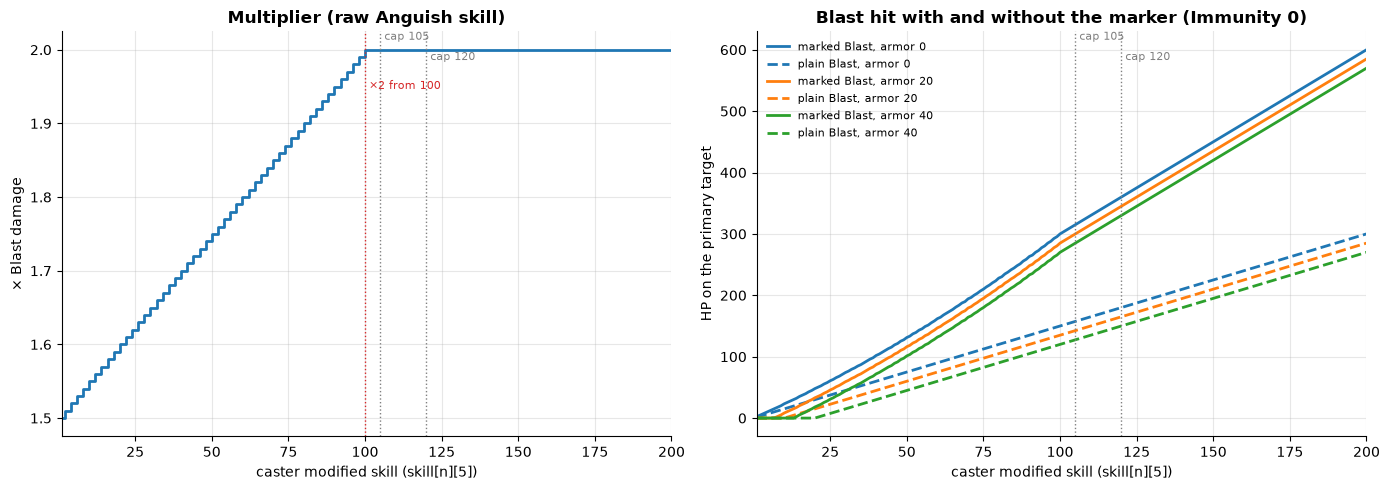

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.step(P, multiplier_pct(P) / 100, where="post")
mm.skill_axis(ax, "× Blast damage", "Multiplier (raw Anguish skill)")
mm.mark_caps(ax, extra=[(100, "×2 from 100")])

ax = axes[1]
pp = mm.spell_power(P, 0, "Harakim")
for armor in (0, 20, 40):
    line, = ax.plot(P, mm.hurt_hp(blast_dam(pp, P), armor, 1), label=f"marked Blast, armor {armor}")
    ax.plot(P, mm.hurt_hp(blast_dam(pp), armor, 1), color=line.get_color(), ls="--", label=f"plain Blast, armor {armor}")
mm.skill_axis(ax, "HP on the primary target", "Blast hit with and without the marker (Immunity 0)")
mm.mark_caps(ax)
ax.legend(fontsize=8)
plt.tight_layout()

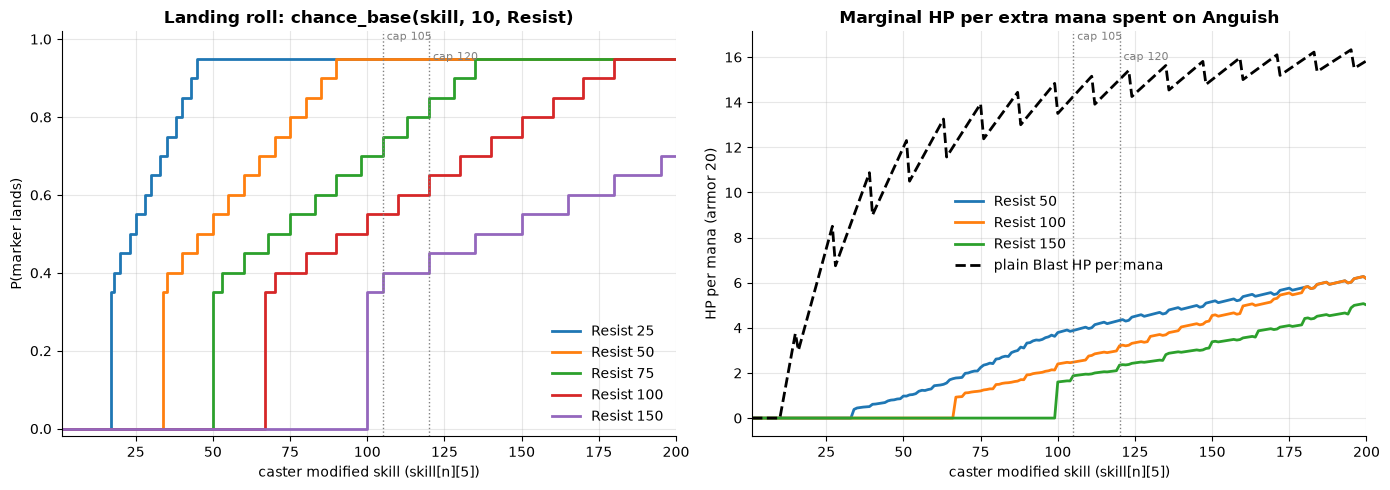

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for r in mm.RESIST_SWEEP:
    ax.step(P, p_marker(P, r), where="post", label=f"Resist {r}")
mm.skill_axis(ax, "P(marker lands)", "Landing roll: chance_base(skill, 10, Resist)")
ax.set_ylim(-0.02, 1.02)
mm.mark_caps(ax)
ax.legend(loc="lower right")

ax = axes[1]
for r in (50, 100, 150):
    (chp, cmana), (php, pmana) = cycle(P, r, armor=20)
    ax.plot(P, (chp - php) / (cmana - pmana), label=f"Resist {r}")
(_, _), (php, pmana) = cycle(P, 50, armor=20)
ax.plot(P, php / pmana, color="black", ls="--", label="plain Blast HP per mana")
mm.skill_axis(ax, "HP per mana (armor 20)", "Marginal HP per extra mana spent on Anguish")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

# Observations

- **Nothing grants it today.** The Harakim talent tree's "Elemental Anguish" node teaches only
  Anguish (Earth). I found no other grant of `SK_ANGUISH_LAVA` in `core/` or `server/`, so the skill
  is reachable only by editing the character directly.
- **It cannot combine with Lava Blast.** Only `compute_blast_damage` (plain Blast and the Seyan'Du
  Free Blast rune) consumes the marker. The Lava Blast talent replaces Blast, so a Harakim with Lava
  Blast has nothing that reads the marker. The two are designed as a pair (lava element) but are
  mutually exclusive.
- **×2 from skill 100.** The multiplier caps at 200% at raw skill 100, below the raise cap, so
  the skill stops mattering early. The marker stores the raw skill, so the target's Immunity does
  not reduce the multiplier.
- **Doubling before armor favours armored targets.** Against armor 40 a marked Blast does ×2.24
  the HP of a plain one; the splash doubles as well.
- **Expensive damage.** A plain Blast at 105 deals 142.5 HP against armor 20 for 10 mana (14 HP
  per mana). Anguish + Blast costs 30 + 19 = 49 mana, because Blast's cost is computed from the
  multiplied damage. Every extra mana buys 3.9 HP against Resist 50 and 2.5 HP against Resist 100
  (the marker lands 95% / 55% of the time with the weaker d20 10).
- **No exhaust makes it a burst, not a rotation cost.** Anguish adds no exhaust, so it fits
  in front of every Blast and doubles the damage per 6 s cycle: 292 HP instead of 142.5 against
  Resist 50 at skill 105.
- **The description is fine but incomplete.** "Empowers your next Blast" omits that the
  empowered Blast costs about twice as much mana.
- **Balance suggestions.** Let Lava Blast consume the marker (and amplify the burn), compute
  Blast's cost from the unmultiplied damage, and grant Anguish (Lava) somewhere in the tree.